<a href="https://colab.research.google.com/github/bluejellyfish83/IntroToGithub/blob/main/PosturalMyo_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Side Posture Analysis (default: Right Side)

Saving Posture 2026-05-06.png to Posture 2026-05-06 (2).png
Forward head offset:  -26 px  ≈ -6.3 cm  (>2.5 cm = significant FHP)
Craniovertebral angle: 76.6°    (>53° normal · 50–53 mild · <50 significant FHP)
Trunk lean:            +5.8°   (+ = forward; <5° = neutral)
Knee angle:            172.8°  (178–182° neutral · <175° chronic bend)


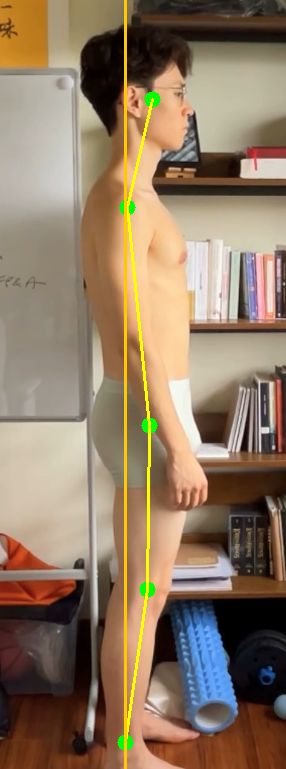

In [3]:
!pip install -q mediapipe
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task

import cv2, math, numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from google.colab import files
from google.colab.patches import cv2_imshow

# 1. Upload your right-side photo
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Load model
base_options = python.BaseOptions(model_asset_path='pose_landmarker.task')
options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    output_segmentation_masks=False,
    num_poses=1)
detector = vision.PoseLandmarker.create_from_options(options)

# 3. Run detection
mp_image = mp.Image.create_from_file(img_path)
result = detector.detect(mp_image)

img = cv2.imread(img_path)
h, w = img.shape[:2]
lm = result.pose_landmarks[0]   # 33 landmarks
def px(i): return np.array([lm[i].x * w, lm[i].y * h])

# 4. Landmark indices (RIGHT side — your image)
# Full list: https://ai.google.dev/edge/mediapipe/solutions/vision/pose_landmarker
R_EAR, R_SHOULDER, R_HIP, R_KNEE, R_ANKLE = 8, 12, 24, 26, 28

ear, shoulder = px(R_EAR), px(R_SHOULDER)
hip, knee, ankle = px(R_HIP), px(R_KNEE), px(R_ANKLE)

# 5. Metrics
def angle(a, b, c):
    ba, bc = a - b, c - b
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-9)
    return math.degrees(math.acos(np.clip(cos, -1, 1)))

# Assuming the subject is facing right in the image (consistent with manual cell)
facing = 1

# Forward head (tragus vs acromion): (ear.x - shoulder.x) * facing (positive = ear in front of shoulder)
fhp_px = (ear[0] - shoulder[0]) * facing

# Craniovertebral angle: angle between ear–C7 line and horizontal
cva = math.degrees(math.atan2(shoulder[1] - ear[1], abs(shoulder[0] - ear[0])))

# Trunk lean (positive = leaning forward, i.e. shoulder ahead of hip)
trunk_lean = math.degrees(math.atan2((shoulder[0] - hip[0]) * facing, hip[1] - shoulder[1]))

# Shoulder protraction (vs hip): horizontal offset of shoulder vs hip
shoulder_protraction_px = (shoulder[0] - hip[0]) * facing

knee_angle = angle(hip, knee, ankle)

# Convert px → cm using your height
YOUR_HEIGHT_CM = 178   # ← change to your real height
# Re-scale using ankle-to-tragus ≈ 0.94 × height (anatomical norm)
body_px = abs(ankle[1] - ear[1]) / 0.94
px_per_cm = body_px / YOUR_HEIGHT_CM

# Calculate cm values for relevant metrics
fhp_cm = fhp_px / px_per_cm
shoulder_protraction_cm = shoulder_protraction_px / px_per_cm

print(f"Forward head (tragus vs acromion): {fhp_cm:+.1f} cm")
print(f"Craniovertebral angle:             {cva:.1f}°")
print(f"Trunk lean (shoulder vs hip):      {trunk_lean:+.1f}°")
print(f"Shoulder protraction (vs hip):     {shoulder_protraction_cm:+.1f} cm")
print(f"Knee angle:                         {knee_angle:.1f}°")

# 6. Draw plumb line + landmarks
for i in [R_EAR, R_SHOULDER, R_HIP, R_KNEE, R_ANKLE]:
    p = px(i).astype(int)
    cv2.circle(img, tuple(p), 8, (0,255,0), -1)
cv2.line(img, tuple(ear.astype(int)), tuple(shoulder.astype(int)), (0,255,255), 2)
cv2.line(img, tuple(shoulder.astype(int)), tuple(hip.astype(int)), (0,255,255), 2)
cv2.line(img, tuple(hip.astype(int)), tuple(knee.astype(int)), (0,255,255), 2)
cv2.line(img, tuple(knee.astype(int)), tuple(ankle.astype(int)), (0,255,255), 2)
# Plumb line through ankle
cv2.line(img, (int(ankle[0]), 0), (int(ankle[0]), h), (0,200,255), 2)
cv2_imshow(img)

In [5]:
import base64, json
from IPython.display import HTML, display
from google.colab import output

# Encode the rendered image (with auto-detected dots) to base64
_, buf = cv2.imencode('.png', img)
b64 = base64.b64encode(buf).decode()

LANDMARKS = [
    'tragus (ear canal)',
    'acromion (bony tip of shoulder)',
    'greater trochanter (hip)',
    'knee center',
    'lateral malleolus (ankle bone)'
]

manual = {}
def save_coords(coords):
    manual.clear()
    manual.update(coords)
    print('✅ Saved manual coords:', list(coords.keys()))
    return 'ok'
output.register_callback('notebook.save_coords', save_coords)

html_template = """
<div style="font-family:system-ui;max-width:900px">
  <div id="status" style="padding:10px;background:#1f2937;color:#fff;font-size:15px;border-radius:6px">
    Click point 1: <b>__FIRST__</b>
  </div>
  <canvas id="cv" style="border:1px solid #888;cursor:crosshair;max-width:100%;display:block;margin-top:8px"></canvas>
  <div style="margin-top:8px">
    <button id="undo" style="padding:6px 12px;margin-right:6px">Undo last</button>
    <button id="reset" style="padding:6px 12px">Reset</button>
  </div>
</div>

<script>
(function() {
  const LM = __LM__;
  const COLORS = ['#fde047','#f0abfc','#67e8f9','#86efac','#fdba74'];
  const b64 = "__B64__";
  const im = new Image();
  im.src = "data:image/png;base64," + b64;

  im.onload = function() {
    const cv = document.getElementById('cv');
    cv.width = im.width;
    cv.height = im.height;
    const ctx = cv.getContext('2d');
    let history = [];

    function status() {
      const el = document.getElementById('status');
      if (history.length >= LM.length) {
        el.innerHTML = '✅ All ' + LM.length + ' points placed. Coords sent to Python — run the next cell.';
        el.style.background = '#065f46';
      } else {
        el.innerHTML = 'Click point ' + (history.length + 1) + ': <b>' + LM[history.length] + '</b>';
      }
    }
    function redraw() {
      ctx.drawImage(im, 0, 0);
      history.forEach(function(p, i) {
        ctx.beginPath();
        ctx.arc(p.x, p.y, 10, 0, 2 * Math.PI);
        ctx.fillStyle = COLORS[i];
        ctx.fill();
        ctx.lineWidth = 2;
        ctx.strokeStyle = '#000';
        ctx.stroke();
        ctx.fillStyle = '#000';
        ctx.font = 'bold 16px sans-serif';
        ctx.fillText(String(i + 1), p.x + 14, p.y + 5);
      });
      status();
    }
    function send() {
      const out = {};
      LM.forEach(function(name, i) {
        out[name] = [history[i].x, history[i].y];
      });
      google.colab.kernel.invokeFunction('notebook.save_coords', [out], {});
    }
    cv.addEventListener('click', function(e) {
      if (history.length >= LM.length) return;
      const r = cv.getBoundingClientRect();
      const x = (e.clientX - r.left) * cv.width / r.width;
      const y = (e.clientY - r.top) * cv.height / r.height;
      history.push({x: x, y: y});
      redraw();
      if (history.length === LM.length) send();
    });
    document.getElementById('undo').onclick = function() {
      history.pop();
      redraw();
    };
    document.getElementById('reset').onclick = function() {
      history = [];
      redraw();
    };
    redraw();
  };
})();
</script>
"""

html_str = (html_template
            .replace('__FIRST__', LANDMARKS[0])
            .replace('__LM__', json.dumps(LANDMARKS))
            .replace('__B64__', b64))

display(HTML(html_str))

✅ Saved manual coords: ['tragus (ear canal)', 'acromion (bony tip of shoulder)', 'greater trochanter (hip)', 'knee center', 'lateral malleolus (ankle bone)']


Forward head (tragus vs acromion): +4.3 cm — mild–moderate FHP (Optimal: 0 to +1.5 cm, Acceptable: +1.5 to +2.5 cm, Mild: +2.5 to +5 cm, Significant: >+5 cm)
Craniovertebral angle:             78.9° — mild dysfunction / borderline mild (Optimal: >85°, Acceptable: 80–85°, Mild: 75–80°, Significant: <75°)
Trunk lean (shoulder vs hip):      -4.3° — mild backward lean (swayback) (Optimal: −2 to +2°, Acceptable: ±2 to ±5°, Mild: ±5 to ±8°, Significant: beyond ±8°)
Shoulder protraction (vs hip):     -4.5 cm — mild–moderate swayback (shoulders behind hips) (Optimal: −1.5 to +1.5 cm, Acceptable: ±1.5 to ±3 cm, Mild: ±3 to ±5 cm, Significant: beyond ±5 cm)
Knee angle:                         173.1° — mild chronic flexion or hyperextension (Optimal: 178–183°, Acceptable: 175–185°, Mild: 172–175° or 185–188°, Significant: <172° or >188°)


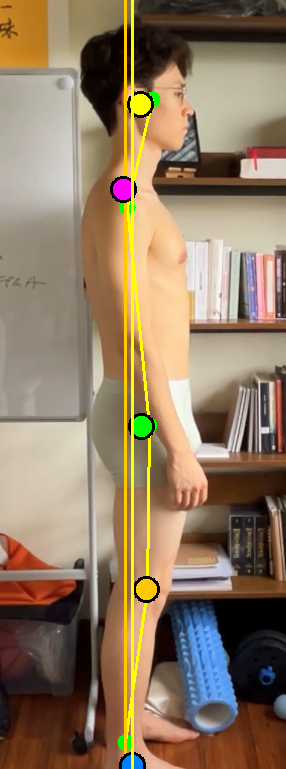

In [11]:
# Pull manual coords back
ear_m      = np.array(manual['tragus (ear canal)'])
shoulder_m = np.array(manual['acromion (bony tip of shoulder)'])
hip_m      = np.array(manual['greater trochanter (hip)'])
knee_m     = np.array(manual['knee center'])
ankle_m    = np.array(manual['lateral malleolus (ankle bone)'])

# Recompute all metrics with manual landmarks
facing = 1   # 1 = facing RIGHT (your case), -1 = facing LEFT

fhp_px = (ear_m[0] - shoulder_m[0]) * facing
cva    = math.degrees(math.atan2(shoulder_m[1] - ear_m[1], abs(shoulder_m[0] - ear_m[0])))
trunk_lean = math.degrees(math.atan2((shoulder_m[0] - hip_m[0]) * facing, hip_m[1] - shoulder_m[1]))
shoulder_protraction_px = (shoulder_m[0] - hip_m[0]) * facing
knee_angle = angle(hip_m, knee_m, ankle_m)

# Re-scale using ankle-to-tragus ≈ 0.94 × height (anatomical norm)
body_px = abs(ankle_m[1] - ear_m[1]) / 0.94
YOUR_HEIGHT_CM = 178   # ← your height
px_per_cm = body_px / YOUR_HEIGHT_CM

fhp_cm = fhp_px / px_per_cm
shoulder_protraction_cm = shoulder_protraction_px / px_per_cm

# Interpretive phrases for each metric
def get_fhp_diagnosis(val):
    if 0 <= val <= 1.5: return "optimal"
    elif 1.5 < val <= 2.5: return "acceptable"
    elif 2.5 < val <= 5: return "mild–moderate FHP"
    elif val > 5: return "significant FHP"
    else: return ""

def get_cva_diagnosis(val):
    if val > 85: return "optimal"
    elif 80 <= val <= 85: return "acceptable"
    elif 75 <= val < 80: return "mild dysfunction / borderline mild"
    elif val < 75: return "significant dysfunction"
    else: return ""

def get_trunk_lean_diagnosis(val):
    if -2 <= val <= 2: return "optimal / neutral"
    elif -5 <= val < -2: return "mild backward lean (swayback)"
    elif 2 < val <= 5: return "mild forward lean"
    elif -8 <= val < -5: return "moderate backward lean"
    elif 5 < val <= 8: return "moderate forward lean"
    elif val < -8: return "significant backward lean"
    elif val > 8: return "significant forward lean"
    else: return ""

def get_shoulder_protraction_diagnosis(val):
    if -1.5 <= val <= 1.5: return "optimal"
    elif -3 <= val < -1.5: return "acceptable backward / swayback"
    elif 1.5 < val <= 3: return "acceptable forward / protraction"
    elif -5 <= val < -3: return "mild–moderate swayback (shoulders behind hips)"
    elif 3 < val <= 5: return "mild–moderate protraction (shoulders ahead of hips)"
    elif val < -5: return "significant swayback"
    elif val > 5: return "significant protraction"
    else: return ""

def get_knee_angle_diagnosis(val):
    if 178 <= val <= 183: return "optimal / neutral"
    elif 175 <= val < 178 or 183 < val <= 185: return "acceptable"
    elif 172 <= val < 175 or 185 < val <= 188: return "mild chronic flexion or hyperextension"
    elif val < 172 or val > 188: return "significant chronic flexion or hyperextension"
    else: return ""

fhp_range = "(Optimal: 0 to +1.5 cm, Acceptable: +1.5 to +2.5 cm, Mild: +2.5 to +5 cm, Significant: >+5 cm)"
cva_range = "(Optimal: >85°, Acceptable: 80–85°, Mild: 75–80°, Significant: <75°)"
trunk_lean_range = "(Optimal: −2 to +2°, Acceptable: ±2 to ±5°, Mild: ±5 to ±8°, Significant: beyond ±8°)"
shoulder_protraction_range = "(Optimal: −1.5 to +1.5 cm, Acceptable: ±1.5 to ±3 cm, Mild: ±3 to ±5 cm, Significant: beyond ±5 cm)"
knee_angle_range = "(Optimal: 178–183°, Acceptable: 175–185°, Mild: 172–175° or 185–188°, Significant: <172° or >188°)"

print(f"Forward head (tragus vs acromion): {fhp_cm:+.1f} cm — {get_fhp_diagnosis(fhp_cm)} {fhp_range}")
print(f"Craniovertebral angle:             {cva:.1f}° — {get_cva_diagnosis(cva)} {cva_range}")
print(f"Trunk lean (shoulder vs hip):      {trunk_lean:+.1f}° — {get_trunk_lean_diagnosis(trunk_lean)} {trunk_lean_range}")
print(f"Shoulder protraction (vs hip):     {shoulder_protraction_cm:+.1f} cm — {get_shoulder_protraction_diagnosis(shoulder_protraction_cm)} {shoulder_protraction_range}")
print(f"Knee angle:                         {knee_angle:.1f}° — {get_knee_angle_diagnosis(knee_angle)} {knee_angle_range}")

# Plumb-line render
out = img.copy()
for p, c in zip([ear_m, shoulder_m, hip_m, knee_m, ankle_m], [(0,255,255),(255,0,255),(0,255,0),(0,200,255),(255,128,0)]):
    cv2.circle(out, tuple(p.astype(int)), 12, c, -1)
    cv2.circle(out, tuple(p.astype(int)), 12, (0,0,0), 2)
cv2.line(out, (int(ankle_m[0]), 0), (int(ankle_m[0]), out.shape[0]), (0,255,255), 2)
cv2_imshow(out)



```
# This is formatted as code
```

## Front-Side Analysis


Saving Front 2026-05-06 at 16.51.52.png to Front 2026-05-06 at 16.51.52.png


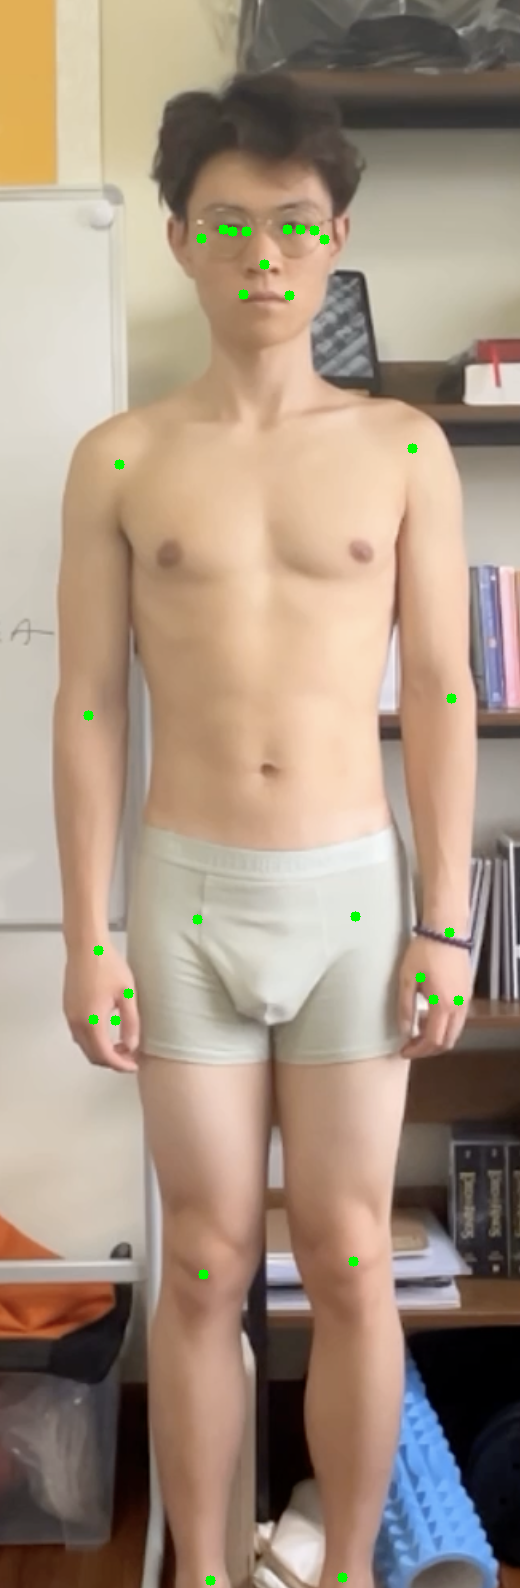

In [12]:
!pip install -q mediapipe
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task

import cv2, math, numpy as np, base64, json
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from google.colab import files, output
from google.colab.patches import cv2_imshow
from IPython.display import HTML, display

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

base_options = python.BaseOptions(model_asset_path='pose_landmarker.task')
options = vision.PoseLandmarkerOptions(base_options=base_options, num_poses=1)
detector = vision.PoseLandmarker.create_from_options(options)
mp_image = mp.Image.create_from_file(img_path)
result = detector.detect(mp_image)

img = cv2.imread(img_path)
h, w = img.shape[:2]
lm = result.pose_landmarks[0]
def px(i): return np.array([lm[i].x * w, lm[i].y * h])

# Draw all auto-detected landmarks for the click editor
out = img.copy()
for i, p in enumerate(lm):
    cv2.circle(out, (int(p.x*w), int(p.y*h)), 5, (0,255,0), -1)
img_drawn = out.copy()
cv2_imshow(out)


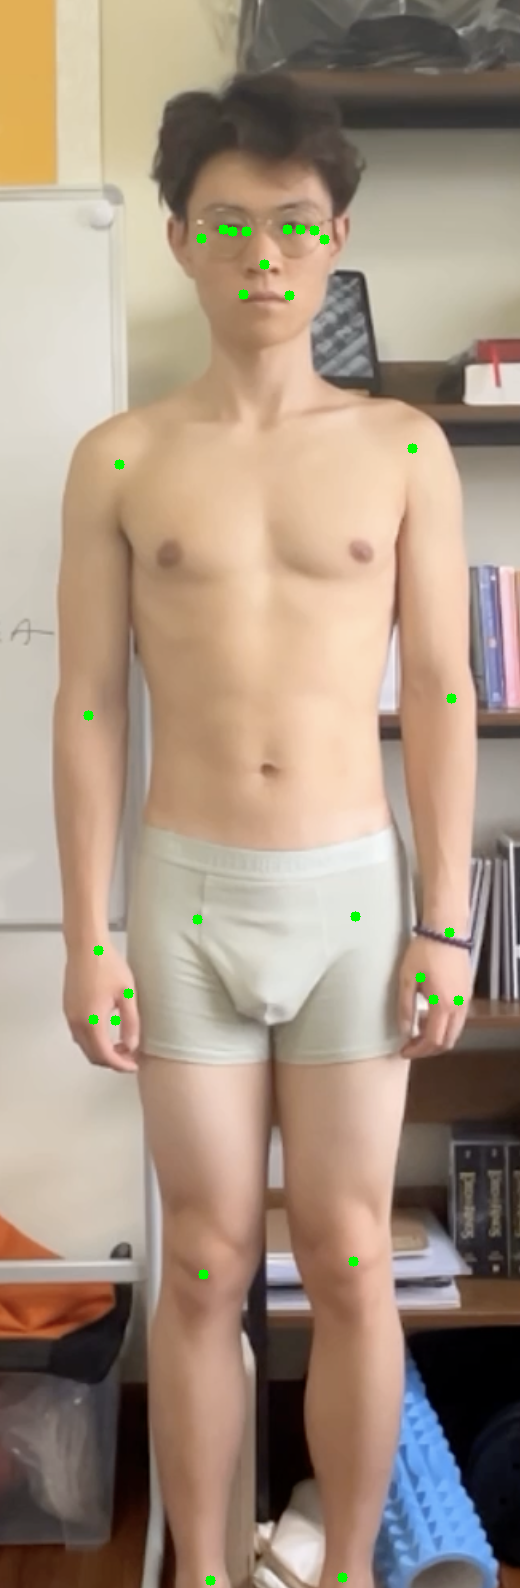

✅ Saved: ['LEFT ear (your left, image right)', 'RIGHT ear (your right, image left)', 'LEFT shoulder (acromion)', 'RIGHT shoulder (acromion)', 'LEFT hip (iliac crest, top of pelvis bone)', 'RIGHT hip (iliac crest)', 'LEFT knee center', 'RIGHT knee center']


In [13]:
LANDMARKS = [
    'LEFT ear (your left, image right)',
    'RIGHT ear (your right, image left)',
    'LEFT shoulder (acromion)',
    'RIGHT shoulder (acromion)',
    'LEFT hip (iliac crest, top of pelvis bone)',
    'RIGHT hip (iliac crest)',
    'LEFT knee center',
    'RIGHT knee center',
]

manual = {}
def save_coords(coords):
    manual.clear(); manual.update(coords)
    print('✅ Saved:', list(coords.keys())); return 'ok'
output.register_callback('notebook.save_coords', save_coords)

_, buf = cv2.imencode('.png', img_drawn)
b64 = base64.b64encode(buf).decode()

html_template = """
<div style="font-family:system-ui;max-width:900px">
  <div id="status" style="padding:10px;background:#1f2937;color:#fff;font-size:15px;border-radius:6px">
    Click point 1: <b>__FIRST__</b>
  </div>
  <canvas id="cv" style="border:1px solid #888;cursor:crosshair;max-width:100%;display:block;margin-top:8px"></canvas>
  <div style="margin-top:8px">
    <button id="undo" style="padding:6px 12px;margin-right:6px">Undo</button>
    <button id="reset" style="padding:6px 12px">Reset</button>
  </div>
</div>
<script>
(function() {
  const LM = __LM__;
  const COLORS = ['#fde047','#f0abfc','#67e8f9','#86efac','#fdba74','#fca5a5','#a5b4fc','#fbcfe8'];
  const im = new Image();
  im.src = "data:image/png;base64,__B64__";
  im.onload = function() {
    const cv = document.getElementById('cv');
    cv.width = im.width; cv.height = im.height;
    const ctx = cv.getContext('2d');
    let history = [];
    function status() {
      const el = document.getElementById('status');
      if (history.length >= LM.length) { el.innerHTML = '✅ Done — run next cell'; el.style.background='#065f46'; }
      else el.innerHTML = 'Click point ' + (history.length + 1) + ': <b>' + LM[history.length] + '</b>';
    }
    function redraw() {
      ctx.drawImage(im, 0, 0);
      history.forEach(function(p, i) {
        ctx.beginPath(); ctx.arc(p.x, p.y, 10, 0, 6.283);
        ctx.fillStyle = COLORS[i]; ctx.fill();
        ctx.lineWidth = 2; ctx.strokeStyle = '#000'; ctx.stroke();
        ctx.fillStyle = '#000'; ctx.font='bold 14px sans-serif';
        ctx.fillText(String(i+1), p.x+13, p.y+5);
      });
      status();
    }
    function send() {
      const out = {}; LM.forEach(function(n,i){ out[n] = [history[i].x, history[i].y]; });
      google.colab.kernel.invokeFunction('notebook.save_coords', [out], {});
    }
    cv.addEventListener('click', function(e) {
      if (history.length >= LM.length) return;
      const r = cv.getBoundingClientRect();
      const x = (e.clientX - r.left) * cv.width / r.width;
      const y = (e.clientY - r.top) * cv.height / r.height;
      history.push({x:x, y:y}); redraw();
      if (history.length === LM.length) send();
    });
    document.getElementById('undo').onclick = function(){ history.pop(); redraw(); };
    document.getElementById('reset').onclick = function(){ history = []; redraw(); };
    redraw();
  };
})();
</script>
"""
display(HTML(html_template
    .replace('__FIRST__', LANDMARKS[0])
    .replace('__LM__', json.dumps(LANDMARKS))
    .replace('__B64__', b64)))

Shoulder tilt:  +2.8°   (+ = LEFT shoulder higher)
Hip tilt:       -1.7°   (+ = LEFT hip higher)
Head tilt:      +2.4°   (+ = head tilted toward LEFT)
Left knee dev:  +4.1 cm  (+ = valgus/knee-in)
Right knee dev: +5.6 cm  (+ = valgus/knee-in)


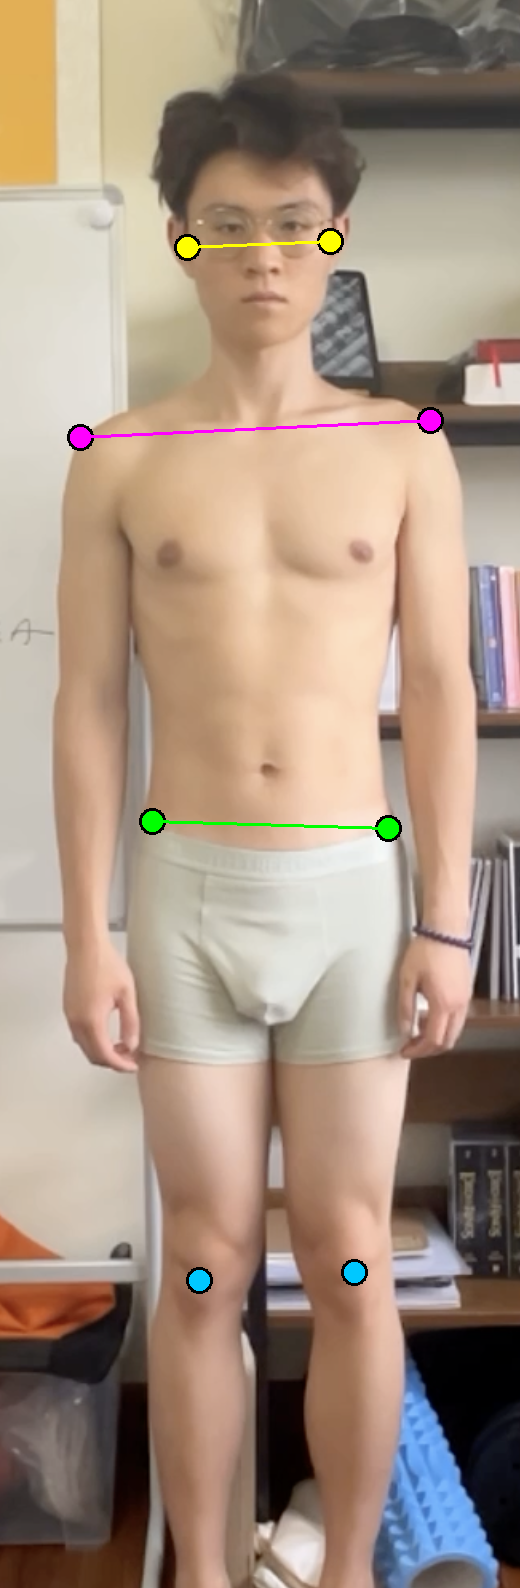

In [15]:
def find(words):
    """First word must match the start of the key (case-insensitive). Other words must appear anywhere."""
    head = words[0].lower()
    rest = [w.lower() for w in words[1:]]
    for k, v in manual.items():
        kl = k.lower()
        if kl.startswith(head) and all(w in kl for w in rest):
            return np.array(v)
    raise KeyError(words)

L_ear = find(['left','ear']);    R_ear = find(['right','ear'])
L_sh  = find(['left','shoulder']); R_sh  = find(['right','shoulder'])
L_hip = find(['left','hip']);    R_hip = find(['right','hip'])
L_kn  = find(['left','knee']);   R_kn  = find(['right','knee'])

# IMPORTANT: in a front-facing photo, your LEFT body is on the IMAGE RIGHT (mirror)
# Tilt sign convention: + = your LEFT side higher (= image right side higher)
def tilt_deg(left_pt, right_pt):
    """Tilt of L–R line from horizontal. + = your-left-higher (=image-right-higher)."""
    # In image: y increases downward. Left body = image right. So if left body higher,
    # left_pt is at IMAGE x > right_pt's x AND lower y. Use right_pt (image-left) – left_pt.
    dx = left_pt[0] - right_pt[0]      # > 0 if left body on image right (normal)
    dy = right_pt[1] - left_pt[1]      # > 0 if right body lower in image = left body higher
    return math.degrees(math.atan2(dy, abs(dx)))

shoulder_tilt = tilt_deg(L_sh, R_sh)
hip_tilt      = tilt_deg(L_hip, R_hip)
head_tilt     = tilt_deg(L_ear, R_ear)

# Scale (use shoulder width as anatomical reference; alt: provide your height)
shoulder_width_px = np.linalg.norm(L_sh - R_sh)
SHOULDER_WIDTH_CM = 42   # ← measure yours: bony tip to bony tip across the back. Adjust.
px_per_cm = shoulder_width_px / SHOULDER_WIDTH_CM

# Knee Q-angle (frontal): angle at knee between hip-knee and knee-ankle
# We don't have ankles clicked here for simplicity — use hip-knee horizontal deviation as proxy
# (knee deviation from hip vertical line; + = valgus / knee-in)
def knee_dev(hip, knee):
    return (hip[0] - knee[0]) / px_per_cm  # cm; sign depends on side

L_knee_dev = (L_hip[0] - L_kn[0]) / px_per_cm   # + = left knee inside hip line
R_knee_dev = (R_kn[0] - R_hip[0]) / px_per_cm   # + = right knee inside hip line

print(f"Shoulder tilt:  {shoulder_tilt:+.1f}°   (+ = LEFT shoulder higher)")
print(f"Hip tilt:       {hip_tilt:+.1f}°   (+ = LEFT hip higher)")
print(f"Head tilt:      {head_tilt:+.1f}°   (+ = head tilted toward LEFT)")
print(f"Left knee dev:  {L_knee_dev:+.1f} cm  (+ = valgus/knee-in)")
print(f"Right knee dev: {R_knee_dev:+.1f} cm  (+ = valgus/knee-in)")

# Render
out = img.copy()
for p, c in [(L_ear,(0,255,255)),(R_ear,(0,255,255)),(L_sh,(255,0,255)),(R_sh,(255,0,255)),
             (L_hip,(0,255,0)),(R_hip,(0,255,0)),(L_kn,(255,200,0)),(R_kn,(255,200,0))]:
    cv2.circle(out, tuple(p.astype(int)), 12, c, -1)
    cv2.circle(out, tuple(p.astype(int)), 12, (0,0,0), 2)
cv2.line(out, tuple(L_sh.astype(int)), tuple(R_sh.astype(int)), (255,0,255), 2)
cv2.line(out, tuple(L_hip.astype(int)), tuple(R_hip.astype(int)), (0,255,0), 2)
cv2.line(out, tuple(L_ear.astype(int)), tuple(R_ear.astype(int)), (0,255,255), 2)
cv2_imshow(out)

#Facial-Myo Analysis

> Add blockquote



Saving Face 2026-05-06 at 17.08.15.png to Face 2026-05-06 at 17.08.15.png
✅ Detected 478 landmarks


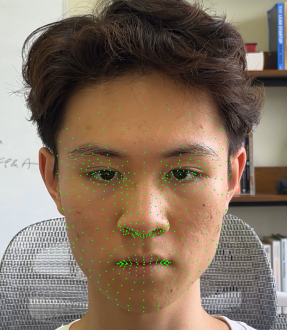

In [16]:
!pip install -q mediapipe
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task

import cv2, math, numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

options = vision.FaceLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path='face_landmarker.task'),
    num_faces=1,
    output_face_blendshapes=False)
detector = vision.FaceLandmarker.create_from_options(options)

mp_image = mp.Image.create_from_file(img_path)
result = detector.detect(mp_image)
img = cv2.imread(img_path)
h, w = img.shape[:2]
lm = result.face_landmarks[0]
print(f"✅ Detected {len(lm)} landmarks")

def p(i): return np.array([lm[i].x * w, lm[i].y * h])

# Sanity check: render all landmarks small
out = img.copy()
for L in lm:
    cv2.circle(out, (int(L.x*w), int(L.y*h)), 1, (0,255,0), -1)
cv2_imshow(cv2.resize(out, (w//2, h//2)))

IPD: 144.4 px → 0.4364 mm/px
Facial midline tilt from vertical: -0.3°  (head should be near 0)

=== HEIGHT (vertical) ASYMMETRY ===
Eye outer canthus                -0.4 mm   (+ = LEFT higher)
Inner brow                       +0.2 mm   (+ = LEFT higher)
Cheekbone                        -0.8 mm   (+ = LEFT higher)
Mouth corner                     +0.9 mm   (+ = LEFT higher)
Gonial angle (jaw)               -1.0 mm   (+ = LEFT higher)

=== DEPTH (forward projection) ASYMMETRY ===
Cheekbone                        -2.2 mm   (+ = LEFT more forward)
Outer canthus                    -1.4 mm   (+ = LEFT more forward)
Inner brow                       -0.4 mm   (+ = LEFT more forward)
Mouth corner                     -0.9 mm   (+ = LEFT more forward)
Gonial angle                     -1.7 mm   (+ = LEFT more forward)
⚠️ z is RELATIVE; trust sign + trends, not absolute mm.

=== NOSE MIDLINE TRACE (top → tip) ===
  nasion              +0.2 mm
  bridge top          +0.2 mm
  bridge upper        -0.0

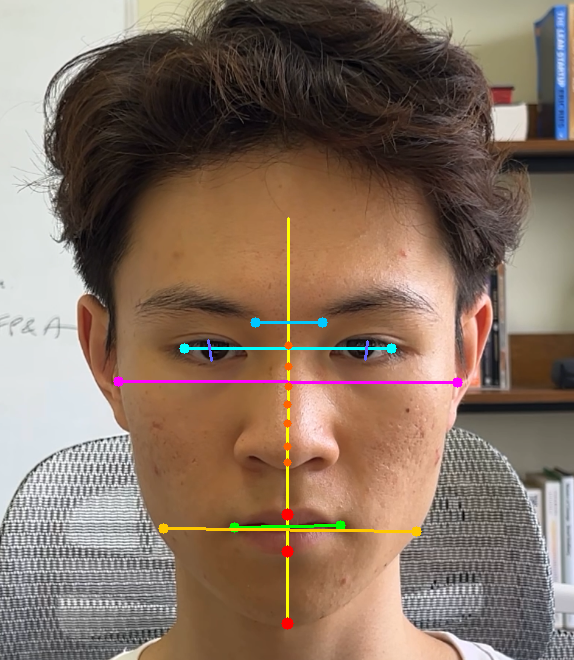

In [20]:
# === Bilateral pairs (subject's left, right) ===
L_eye_outer, R_eye_outer = 263, 33
L_iris,      R_iris      = 473, 468
L_brow_in,   R_brow_in   = 285, 55
L_cheek,     R_cheek     = 454, 234
L_mouth,     R_mouth     = 291, 61
L_jaw,       R_jaw       = 397, 172

MIDLINE = [10, 151, 9, 8, 168, 6, 197, 195, 5, 4, 1, 19, 94, 2, 164, 0, 13, 14, 17, 18, 200, 199, 175, 152]

# Scale via inter-pupillary distance
IPD_MM = 63.0   # ← measure yours for accuracy
ipd_px = np.linalg.norm(p(L_iris) - p(R_iris))
mm_per_px = IPD_MM / ipd_px

# Fit midline as line x = a*y + b
mid_pts = np.array([p(i) for i in MIDLINE])
ys, xs = mid_pts[:,1], mid_pts[:,0]
a, b = np.polyfit(ys, xs, 1)
midline_angle_deg = math.degrees(math.atan(a))

def perp_dist(pt):
    return (pt[0] - a*pt[1] - b) / math.sqrt(1 + a*a)

# Define p3 to extract 3D coordinates (x, y, z)
def p3(i): return np.array([lm[i].x * w, lm[i].y * h, lm[i].z * w]) # z is relative, so scale by w for consistency

print(f'IPD: {ipd_px:.1f} px → {mm_per_px:.4f} mm/px')
print(f'Facial midline tilt from vertical: {midline_angle_deg:+.1f}°  (head should be near 0)\n')

print('=== HEIGHT (vertical) ASYMMETRY ===')
def height_asym(L_idx, R_idx, label):
    L, R = p(L_idx), p(R_idx)
    d = (R[1] - L[1]) * mm_per_px
    print(f'{label:30s} {d:+6.1f} mm   (+ = LEFT higher)')
    return d
height_asym(L_eye_outer, R_eye_outer, 'Eye outer canthus')
height_asym(L_brow_in,   R_brow_in,   'Inner brow')
height_asym(L_cheek,     R_cheek,     'Cheekbone')
height_asym(L_mouth,     R_mouth,     'Mouth corner')
height_asym(L_jaw,       R_jaw,       'Gonial angle (jaw)')

print('\n=== DEPTH (forward projection) ASYMMETRY ===')
def depth_asym(L_idx, R_idx, label):
    L, R = p3(L_idx), p3(R_idx)
    d = (R[2] - L[2]) * mm_per_px
    print(f'{label:30s} {d:+6.1f} mm   (+ = LEFT more forward)')
    return d
depth_asym(L_cheek,     R_cheek,     'Cheekbone')
depth_asym(L_eye_outer, R_eye_outer, 'Outer canthus')
depth_asym(L_brow_in,   R_brow_in,   'Inner brow')
depth_asym(L_mouth,     R_mouth,     'Mouth corner')
depth_asym(L_jaw,       R_jaw,       'Gonial angle')
print('⚠️ z is RELATIVE; trust sign + trends, not absolute mm.')

print('\n=== NOSE MIDLINE TRACE (top → tip) ===')
NOSE_POINTS = [168, 6, 197, 195, 5, 4, 1]
NOSE_NAMES  = ['nasion','bridge top','bridge upper','bridge mid','bridge lower','subnasal','nose tip']
for idx, name in zip(NOSE_POINTS, NOSE_NAMES):
    d = perp_dist(p(idx)) * mm_per_px
    print(f'  {name:18s} {d:+5.1f} mm')
print('(+ = deviated to subject\'s LEFT)')

print('\n=== OTHER MIDLINE DEVIATIONS ===')
for idx, name in [(152, 'Chin tip'), (0, 'Upper lip center (philtrum)'), (17, 'Lower lip center')]:
    d = perp_dist(p(idx)) * mm_per_px
    print(f'  {name:30s} {d:+5.1f} mm   (+ = LEFT)')

print('\n=== MID-FACE LENGTH (eye outer → mouth corner) ===')
L_mid = np.linalg.norm(p(L_eye_outer) - p(L_mouth)) * mm_per_px
R_mid = np.linalg.norm(p(R_eye_outer) - p(R_mouth)) * mm_per_px
print(f'  Left:  {L_mid:.1f} mm')
print(f'  Right: {R_mid:.1f} mm')
print(f'  Diff:  {L_mid - R_mid:+.1f} mm   (+ = LEFT longer)')

print('\n=== EYE APERTURE & WIDTH ===')
L_ap = abs(p(386)[1] - p(374)[1]) * mm_per_px
R_ap = abs(p(159)[1] - p(145)[1]) * mm_per_px
L_ew = np.linalg.norm(p(263) - p(362)) * mm_per_px
R_ew = np.linalg.norm(p(33)  - p(133)) * mm_per_px
print(f'  Aperture: L {L_ap:.1f} mm  vs  R {R_ap:.1f} mm  →  diff {L_ap-R_ap:+.1f} mm  (+ = L more open)')
print(f'  Width:    L {L_ew:.1f} mm  vs  R {R_ew:.1f} mm  →  diff {L_ew-R_ew:+.1f} mm  (+ = L wider)')
print(f'  Aperture/Width ratio: L {L_ap/L_ew:.2f}  vs  R {R_ap/R_ew:.2f}')
print('  Ratio diff >0.05 = visible eye-shape asymmetry')

print('\n=== FACE WIDTH RATIOS ===')
bizyg = np.linalg.norm(p(L_cheek) - p(R_cheek)) * mm_per_px
bigon = np.linalg.norm(p(L_jaw)   - p(R_jaw))   * mm_per_px
print(f'  Bizygomatic (cheek): {bizyg:.1f} mm')
print(f'  Bigonial (jaw):      {bigon:.1f} mm')
print(f'  Cheek/jaw ratio:     {bizyg/bigon:.2f}  (>1.30 good maxilla)')

# === Visualization ===
out = img.copy()
y_top, y_bot = int(p(10)[1]), int(p(152)[1])
x_top, x_bot = int(a*y_top + b), int(a*y_bot + b)
cv2.line(out, (x_top, y_top), (x_bot, y_bot), (0, 255, 255), 2)

pairs = [
    (L_eye_outer, R_eye_outer, (255,255,0)),
    (L_brow_in,   R_brow_in,   (255,200,0)),
    (L_cheek,     R_cheek,     (255,0,255)),
    (L_mouth,     R_mouth,     (0,255,0)),
    (L_jaw,       R_jaw,       (0,200,255)),
]
for li, ri, color in pairs:
    L, R = p(li).astype(int), p(ri).astype(int)
    cv2.line(out, tuple(L), tuple(R), color, 2)
    cv2.circle(out, tuple(L), 5, color, -1)
    cv2.circle(out, tuple(R), 5, color, -1)

for idx in NOSE_POINTS:
    cv2.circle(out, tuple(p(idx).astype(int)), 4, (0, 100, 255), -1)

for top, bot in [(386, 374), (159, 145)]:
    cv2.line(out, tuple(p(top).astype(int)), tuple(p(bot).astype(int)), (255, 100, 100), 2)

for idx in [152, 0, 17]:
    cv2.circle(out, tuple(p(idx).astype(int)), 6, (0, 0, 255), -1)

cv2_imshow(out)